# Notebook 1: Data Cleaning, Feature Engineering and Exploratory Analysis

**Project:** Luxury Watch Resale Price Analysis (final capstone)
**Author:** Mina Andrawos

This is the first of four notebooks. It prepares the data that the modeling notebooks use, and explores which watch features are linked to higher resale prices.

| # | Notebook | Purpose |
|---|---|---|
| **1** | **Data cleaning and EDA (this notebook)** | Clean both datasets, engineer features, explore price drivers, run statistical tests |
| 2 | [Model training and tuning](02_model_training_and_tuning.ipynb) | Compare five model types with cross-validation and grid search |
| 3 | [Model evaluation and insights](03_model_evaluation_and_insights.ipynb) | Test-set results, error analysis, feature importance, price premiums |
| 4 | [Box, papers and seller analysis](04_box_papers_and_seller_analysis.ipynb) | Model the second dataset to measure the value of box, papers and seller reputation |

### Business understanding
Luxury watches are bought both as a passion and as an alternative investment, and many are later resold on the secondary market, including online marketplaces. Collectors and investors face a similar question: **What factors drive the resale prices of luxury watches?** 

**Research question:** In module 16, I posed the research question simply as *Research factors affecting the resale price of luxury watches*. For the purpose of the capstone, the original research question deserves some more detail and context, in order to articulate the key project requirements: *What combination of features (brand, model line, materials, movement, condition, box & papers, age) most significantly affects the resale price of a luxury watch, and how accurately can resale price be predicted from them?*

### What changed since the initial report
The [initial capstone](https://github.com/minaandrawos/berkeley-ai-ml-certificate/tree/main/capstone-initial) built a Ridge Regression baseline on Dataset 2 (R² = 0.80, typical error 37%). It listed three next steps, and this final project acts on key aspects of these steps (reference numbers and full text analysis are left for future work):
1. **Model names** (e.g. Nautilus, Daytona, Royal Oak) are extracted from Dataset 1, the larger dataset, and used as features.
2. **Simple text features**: keyword flags for complications (chronograph, tourbillon, perpetual calendar...), diamonds and limited editions, taken from the listing titles and model names.
3. **Non-linear models** (Random Forest, Gradient Boosting) are tuned with cross-validated grid search (Notebook 2).

For consistency, and to offer a complete final capstone submission, we'll repeat some of the steps done in the initial capstone report submission. 

### Notebook outline
1. Setup
2. Dataset 1 (Luxury Watch Listings): loading, cleaning, outliers, feature engineering
3. Dataset 1: exploratory data analysis and statistical tests
4. Dataset 2 (Watch Market Dataset): cleaning and feature engineering
5. Dataset 2: exploratory data analysis and statistical tests
6. Cross-checking the two datasets
7. Saving the cleaned data
8. Summary of findings

## 1. Setup
Libraries are imported with their standard aliases. A shared plot style, a dollar formatter for price axes, and a helper to save figures used in the README are defined here.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter, NullFormatter
from scipy import stats
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)

DATA_DIR = Path("data")
PROCESSED_DIR = DATA_DIR / "processed"
IMAGES_DIR = Path("images")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
IMAGES_DIR.mkdir(exist_ok=True)

# Formats price axes as dollars (e.g. $12,500) instead of scientific notation
dollar_format = FuncFormatter(lambda value, _: f"${value:,.0f}")


def format_p(p_value):
    """p-values below the smallest representable number are reported as '< 1e-300' instead of 0."""
    return f"= {p_value:.2g}" if p_value > 0 else "< 1e-300"


def save_figure(fig, filename):
    """Save a figure to the images/ folder so the README can show it."""
    fig.savefig(IMAGES_DIR / filename, dpi=110, bbox_inches="tight")

## 2. Dataset 1: Luxury Watch Listings
[Source: Kaggle](https://www.kaggle.com/datasets/philmorekoung11/luxury-watch-listings). About 285,000 watch listings, with the listing title (`name`), price, brand, **model**, reference number, movement, case and bracelet material, year of production, condition, gender and case size.

### 2.1 Loading and profiling

In [2]:
listings_raw = pd.read_csv(DATA_DIR / "Watches-ds-1.csv", low_memory=False)

# "Unnamed: 0" is the row index saved with the CSV. It is unique per row,
# so duplicate detection cannot find any match until it is dropped.
listings_raw = listings_raw.drop(columns="Unnamed: 0")
print(f"Dataset 1 shape: {listings_raw.shape}")
display(listings_raw.head(3))

Dataset 1 shape: (284491, 13)


,name,price,brand,model,ref,mvmt,casem,bracem,yop,cond,sex,size,condition
0,Audemars Piguet Royal Oak Offshore Chronograph...,"$43,500",Audemars Piguet,Royal Oak Offshore Chronograph,26237ST.OO.1000ST.01,NaN,NaN,NaN,2019,Unworn,Men's watch/Unisex,42 mm,NaN
1,Audemars Piguet Royal Oak Selfwinding\n39mm Bl...,"$71,500",Audemars Piguet,Royal Oak Selfwinding,15300ST.OO.1220ST.02,NaN,NaN,NaN,2012,Very good,Men's watch/Unisex,39 mm,NaN
2,Audemars Piguet Royal Oak Chronograph\nBlue Di...,"$79,191",Audemars Piguet,Royal Oak Chronograph,26331ST,Automatic,Steel,Steel,Unknown,Unworn,NaN,41 mm,NaN


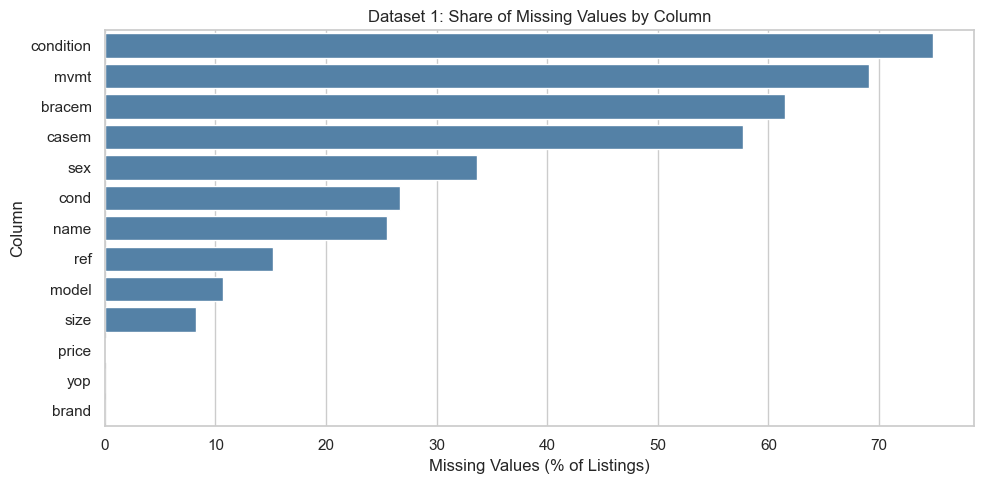

Listings per brand (smallest 10):
brand
Richard Mille    1242
Sinn              677
NOMOS               3
Edox                2
Montblanc           2
Tissot              1
Hamilton            1
Meistersinger       1
Rado                1
Ebel                1


In [3]:
# Share of missing values per column
missing_share = listings_raw.isna().mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=missing_share.values * 100, y=missing_share.index, color="steelblue", ax=ax)
ax.set_title("Dataset 1: Share of Missing Values by Column")
ax.set_xlabel("Missing Values (% of Listings)")
ax.set_ylabel("Column")
plt.tight_layout()
plt.show()

print("Listings per brand (smallest 10):")
print(listings_raw["brand"].value_counts().tail(10).to_string())

**Observation:** Brand and the price field are almost always filled in (though about 14,000 prices are *"Price on request"*), but movement, case material and bracelet material are missing for 58-69% of listings, and condition is split across two columns (`cond` and `condition`). The dataset covers 20 major brands with hundreds to tens of thousands of listings each, plus 8 brands with only 1-3 listings, which are too few to learn anything from.

### 2.2 Cleaning
> *As was done in the initial report: price parsing, year extraction, merging the condition columns, filling missing categories and removing duplicates. New here: the approximate-year flag, the brand filter, case-size parsing and grouping the low condition grades.*

Plan (the first four steps are carried over from the initial report, except the approximate-year flag and the grouping of the low condition grades, which are new):
- **Price** is text such as `$43,500`. Symbols and commas are stripped; listings without a numeric price (*"Price on request"* or blank) are dropped because price is the target.
- **Year of production** contains values such as `2022 (Approximation)` or `Unknown`. The 4-digit year is extracted and kept if it is between 1900 and 2024 (latest production year that actually appears in the data); an `is_year_approx` flag records approximate years.
- **Condition** is merged from the two condition columns. The rare *Poor* and *Incomplete* grades are grouped with *Fair*.
- Missing categorical values are filled with `Unknown`, so the models can learn from the fact that a value is missing.
- **New:** brands with fewer than 50 listings are removed (the 8 brands above).
- **New:** case **size** is parsed into millimetres (for rectangular cases such as `41 x 48 mm`, the first number, i.e. the width, is used).
- Exact duplicate listings are removed.

In [4]:
MIN_YEAR, MAX_YEAR = 1900, 2024   # 2024 is the latest production year in the data
MIN_BRAND_LISTINGS_DS1 = 50


def clean_price(price_series):
    """Strip currency symbols/commas and convert to float; non-numeric text becomes NaN."""
    stripped = price_series.astype(str).str.replace(r"[$£€,]", "", regex=True).str.strip()
    return pd.to_numeric(stripped, errors="coerce")


def clean_year(year_series):
    """Extract a plausible 4-digit production year; anything else becomes NaN."""
    years = pd.to_numeric(year_series.astype(str).str[:4], errors="coerce")
    return years.where(years.between(MIN_YEAR, MAX_YEAR))


def parse_size_mm(size_series):
    """Take the first number in strings like '40 mm' or '41 x 48 mm'; keep 15-60 mm only."""
    first_number = size_series.astype(str).str.extract(r"(\d+(?:[.,]\d+)?)")[0].str.replace(",", ".")
    size_mm = pd.to_numeric(first_number, errors="coerce")
    return size_mm.where(size_mm.between(15, 60))


listings = listings_raw.copy()
listings["price"] = clean_price(listings["price"])
print(f"Listings without a numeric price (dropped): {listings['price'].isna().sum():,}")
listings = listings.dropna(subset=["price"])

listings["year"] = clean_year(listings["yop"])
listings["is_year_approx"] = listings["yop"].str.contains("Approximation", na=False).astype(int)
listings["size_mm"] = parse_size_mm(listings["size"])

# Merge the two condition columns (prefer 'cond' when both exist), then group the rare low grades
listings["condition"] = (listings["cond"].fillna(listings["condition"])
                         .replace({"Poor": "Fair/Poor", "Incomplete": "Fair/Poor", "Fair": "Fair/Poor"}))

# Keep only brands with enough listings to learn from
brand_counts = listings["brand"].value_counts()
listings = listings[listings["brand"].map(brand_counts) >= MIN_BRAND_LISTINGS_DS1]

categorical_cols_ds1 = ["model", "mvmt", "casem", "bracem", "condition", "sex"]
listings[categorical_cols_ds1] = listings[categorical_cols_ds1].fillna("Unknown")
listings["name"] = listings["name"].fillna("")

listings = listings.drop(columns=["yop", "cond", "size"])
rows_before = len(listings)
listings = listings.drop_duplicates()
print(f"Duplicate listings removed: {rows_before - len(listings):,}")
print(f"Brands kept: {listings['brand'].nunique()}")
print(f"Dataset 1 shape after cleaning: {listings.shape}")

Listings without a numeric price (dropped): 14,665
Duplicate listings removed: 9,108
Brands kept: 20
Dataset 1 shape after cleaning: (260706, 13)


### 2.3 Outlier analysis
> *As was done in the initial report: the raw-price IQR check and the outlier rules (USD 50 floor + 3 x IQR on log price) are repeated here so the cleaned data can be rebuilt from the raw files.*

As shown in the initial report, the standard 1.5 x IQR rule on **raw** price would remove most of the high-end market. The cell below repeats that check for four high-end brands.

In [5]:
MIN_PLAUSIBLE_PRICE = 50


def iqr_bounds(values, k):
    """Return the (lower, upper) bounds of the IQR rule with multiplier k."""
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


raw_low, raw_high = iqr_bounds(listings["price"], k=1.5)
flagged_by_raw_rule = ~listings["price"].between(raw_low, raw_high)
print(f"Raw-price 1.5 x IQR upper bound: ${raw_high:,.0f}, flags {flagged_by_raw_rule.mean():.1%} of listings")
display(
    flagged_by_raw_rule.groupby(listings["brand"]).mean()
    .loc[["Rolex", "Patek Philippe", "Audemars Piguet", "Richard Mille"]]
    .rename("share flagged by raw-price rule").to_frame().style.format("{:.0%}")
)

Raw-price 1.5 x IQR upper bound: $35,091, flags 11.3% of listings


,share flagged by raw-price rule
brand,
Rolex,16%
Patek Philippe,68%
Audemars Piguet,69%
Richard Mille,99%


**Result:** the raw-price rule would discard the majority of Patek Philippe, Audemars Piguet and Richard Mille listings: the luxury segment itself, not data errors. The same two rules as the initial report are used instead:
1. a **USD 50 price floor** (27 listings in Dataset 1 and 85 in Dataset 2), and
2. **3 x IQR on log10(price)**, the conventional bound for *extreme* outliers, applied on the log scale where prices are roughly bell-shaped.

In [6]:
def remove_price_outliers(df, price_col):
    """Drop prices below the floor or outside 3 x IQR on the log10 scale."""
    log_price = np.log10(df[price_col])
    log_low, log_high = iqr_bounds(log_price, k=3)
    keep = (df[price_col] >= MIN_PLAUSIBLE_PRICE) & log_price.between(log_low, log_high)
    print(f"Log-scale bounds: ${10 ** log_low:,.0f} to ${10 ** log_high:,.0f}; "
          f"listings under ${MIN_PLAUSIBLE_PRICE}: {(df[price_col] < MIN_PLAUSIBLE_PRICE).sum():,}")
    print(f"Rows removed: {(~keep).sum():,} ({(~keep).mean():.2%})")
    return df[keep].copy()


listings = remove_price_outliers(listings, "price")
print(f"Dataset 1 shape after outlier removal: {listings.shape}")

Log-scale bounds: $20 to $2,391,476; listings under $50: 27
Rows removed: 58 (0.02%)
Dataset 1 shape after outlier removal: (260648, 13)


### 2.4 Feature engineering
New features created for the final project:
- **`model_line`**: the model name combined with the brand (e.g. `Patek Philippe | Nautilus`), so that similarly named models from different brands are not mixed. Model lines with fewer than 20 listings are grouped into `<brand> | Other`, and listings without a model become `<brand> | Unknown`.
- **Text flags from the listing title and model name** (1 = mentioned): chronograph, GMT / world time, calendar complication (perpetual or annual calendar), tourbillon or minute repeater, moon phase, diamonds, skeleton dial and limited edition. Titles are missing for about a quarter of listings, so the flags miss features that are not mentioned, and simple keyword matching can occasionally flag a listing by mistake.
- **`watch_age`** (2024 minus production year) and **`year_missing`**.
- Rare case and bracelet materials (fewer than 100 listings) are grouped into `Other`.
- **`log_price`** = log10(price), the modeling target (justified in section 3.1).

In [7]:
MIN_MODEL_LISTINGS = 20 
MIN_MATERIAL_LISTINGS = 100
DATA_COLLECTION_YEAR = 2024


def group_rare(series, min_count, other_label="Other"):
    """Replace categories that appear fewer than min_count times with other_label."""
    counts = series.value_counts()
    return series.where(series.map(counts) >= min_count, other_label)


# Model line, qualified by brand
model_line = listings["brand"] + " | " + listings["model"]
model_counts = model_line.value_counts()
is_rare_model = (model_line.map(model_counts) < MIN_MODEL_LISTINGS) & (listings["model"] != "Unknown")
listings["model_line"] = model_line.where(~is_rare_model, listings["brand"] + " | Other")

# Keyword flags from the listing title + model name (regular expressions, case-insensitive)
TEXT_FLAGS = {
    "is_chronograph": r"chronograph|cosmograph|\bchrono\b",
    "is_gmt": r"\bgmt\b|world ?time|dual time",
    "is_calendar_complication": r"perpetual|annual calendar|quanti[eè]me perp",
    "is_tourbillon_or_repeater": r"tourbillon|minute repeater|r[eé]p[eé]tition minutes",
    "is_moonphase": r"moon ?phase|phases? de lune|mondphase",
    "has_diamonds": r"diamond|diamant|\bpav[eé]\b",
    "is_skeleton": r"skeleton|squelette|openworked",
    "is_limited_edition": r"limited|\bltd\b",
}
listing_text = (listings["name"] + " " + listings["model"]).str.lower()
for flag, pattern in TEXT_FLAGS.items():
    listings[flag] = listing_text.str.contains(pattern, regex=True).astype(int)

listings["watch_age"] = DATA_COLLECTION_YEAR - listings["year"]
listings["year_missing"] = listings["year"].isna().astype(int)
listings["casem"] = group_rare(listings["casem"], MIN_MATERIAL_LISTINGS)
listings["bracem"] = group_rare(listings["bracem"], MIN_MATERIAL_LISTINGS)
listings["log_price"] = np.log10(listings["price"])

# Friendlier column names for plots and models
listings = listings.rename(columns={"mvmt": "movement", "casem": "case_material",
                                    "bracem": "bracelet_material", "sex": "gender"})

print(f"Distinct model lines: {listings['model_line'].nunique()}, e.g. 'Rolex | Submariner'"
      f" (from {listings['model'].nunique()} raw model names, e.g. 'Daytona','Nautilus'..etc )")
# Skewness of 0 means symmetric; large positive values mean a long right tail
print(f"Skewness of price: {listings['price'].skew():.1f}, of log_price: {listings['log_price'].skew():.3f}")
display(listings[list(TEXT_FLAGS)].mean().rename("share of listings").to_frame().T.style.format("{:.1%}"))
print("Highest limited-edition shares by brand: " + ", ".join(
    f"{brand} {share:.1%}" for brand, share in
    listings.groupby("brand")["is_limited_edition"].mean().nlargest(3).items()))

Distinct model lines: 725, e.g. 'Rolex | Submariner' (from 938 raw model names, e.g. 'Daytona','Nautilus'..etc )
Skewness of price: 13.3, of log_price: 0.000


,is_chronograph,is_gmt,is_calendar_complication,is_tourbillon_or_repeater,is_moonphase,has_diamonds,is_skeleton,is_limited_edition
share of listings,10.0%,3.9%,3.5%,0.3%,0.6%,2.6%,0.4%,2.1%


Highest limited-edition shares by brand: Sinn 11.2%, Seiko 9.0%, Oris 8.0%


**Result:** the 938 raw model names become 725 brand-qualified model lines. Chronographs are the most common flagged feature (10% of listings); tourbillons, moon phases and skeleton dials are rare (under 1%). The log transform turns a heavily skewed price (skewness 13.3) into an almost perfectly symmetric target (skewness about 0).

## 3. Dataset 1: Exploratory Data Analysis

### 3.1 Price distribution
> *As was done in the initial report: the linear vs log price histograms and the reason for predicting log price.*

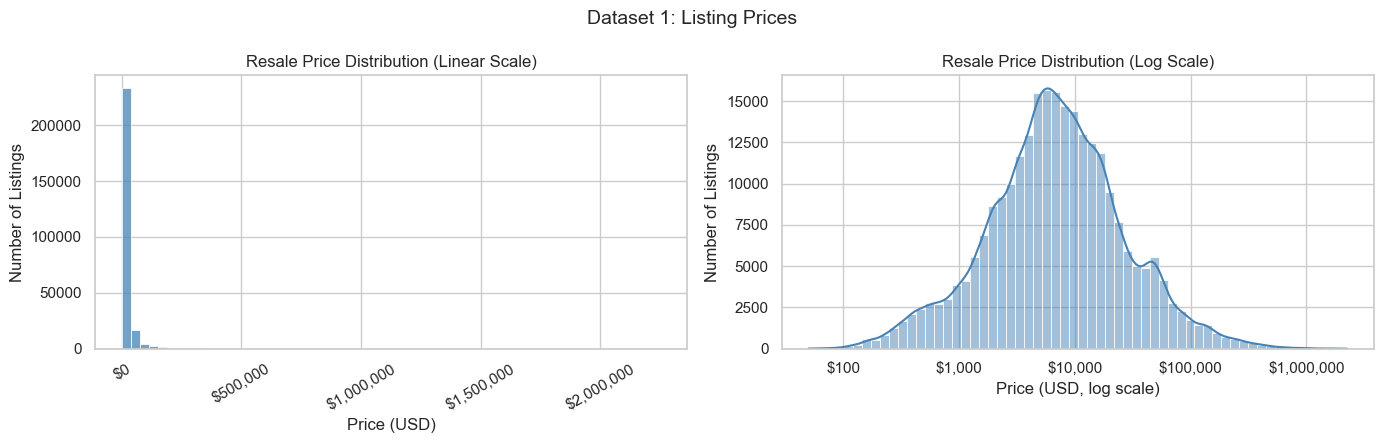

,count,mean,std,min,10%,25%,50%,75%,90%,max
price (USD),"260,648","18,040","46,873",50,"1,211","2,971","6,775","15,818","39,950","2,250,000"


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(listings["price"], bins=60, color="steelblue", ax=axes[0])
axes[0].set_title("Resale Price Distribution (Linear Scale)")
axes[0].set_xlabel("Price (USD)")
axes[0].tick_params(axis="x", rotation=30)

sns.histplot(listings["price"], bins=60, log_scale=True, kde=True, color="steelblue", ax=axes[1])
axes[1].set_title("Resale Price Distribution (Log Scale)")
axes[1].set_xlabel("Price (USD, log scale)")

for ax in axes:
    ax.xaxis.set_major_formatter(dollar_format)
    ax.set_ylabel("Number of Listings")

fig.suptitle("Dataset 1: Listing Prices", fontsize=14)
plt.tight_layout()
plt.show()

display(listings["price"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).to_frame("price (USD)").T
        .style.format("{:,.0f}"))

**Observation:** On a linear scale almost all listings are squeezed into the first few bars, with a long tail up to USD 2.25 million. On a log scale the distribution is close to bell-shaped. The **median listing is USD 6,775** while the mean is USD 18,040, pulled up by a small number of very expensive watches; 80% of listings fall between about USD ~1,200 and USD ~40,000. This is why the models predict `log10(price)`: errors become *relative* (being 20% off counts the same for a USD 2,000 and a USD 200,000 watch), and a few six-figure watches no longer dominate the fit.

### 3.2 Brand and model line
> *As was done in the initial report: the price-by-brand boxplot (first chart). New here: the model-line chart and the brand vs model-line comparison.*

Brand was the dominant price driver in the initial report. Dataset 1 also has model names, so the question here is: **how much do prices vary between model lines of the *same* brand?**

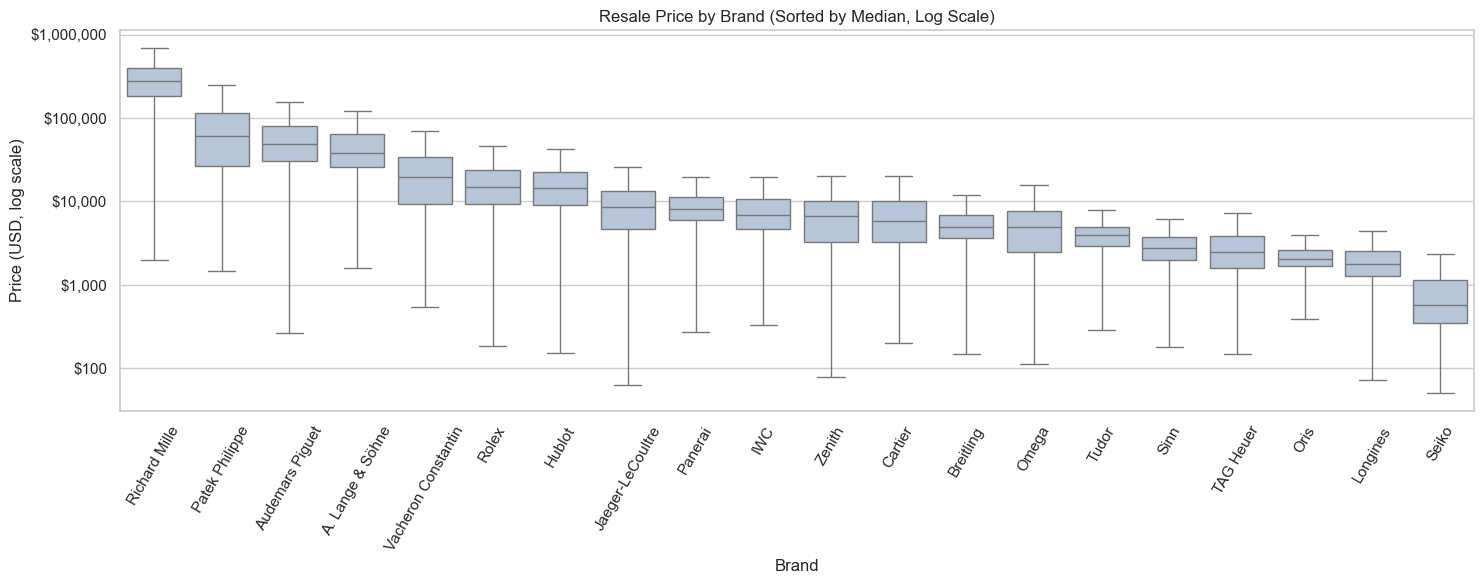

In [9]:
brand_order = listings.groupby("brand")["price"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(15, 6))
sns.boxplot(data=listings, x="brand", y="price", order=brand_order, color="lightsteelblue",
            showfliers=False, ax=ax)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(dollar_format)
ax.set_title("Resale Price by Brand (Sorted by Median, Log Scale)")
ax.set_xlabel("Brand")
ax.set_ylabel("Price (USD, log scale)")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

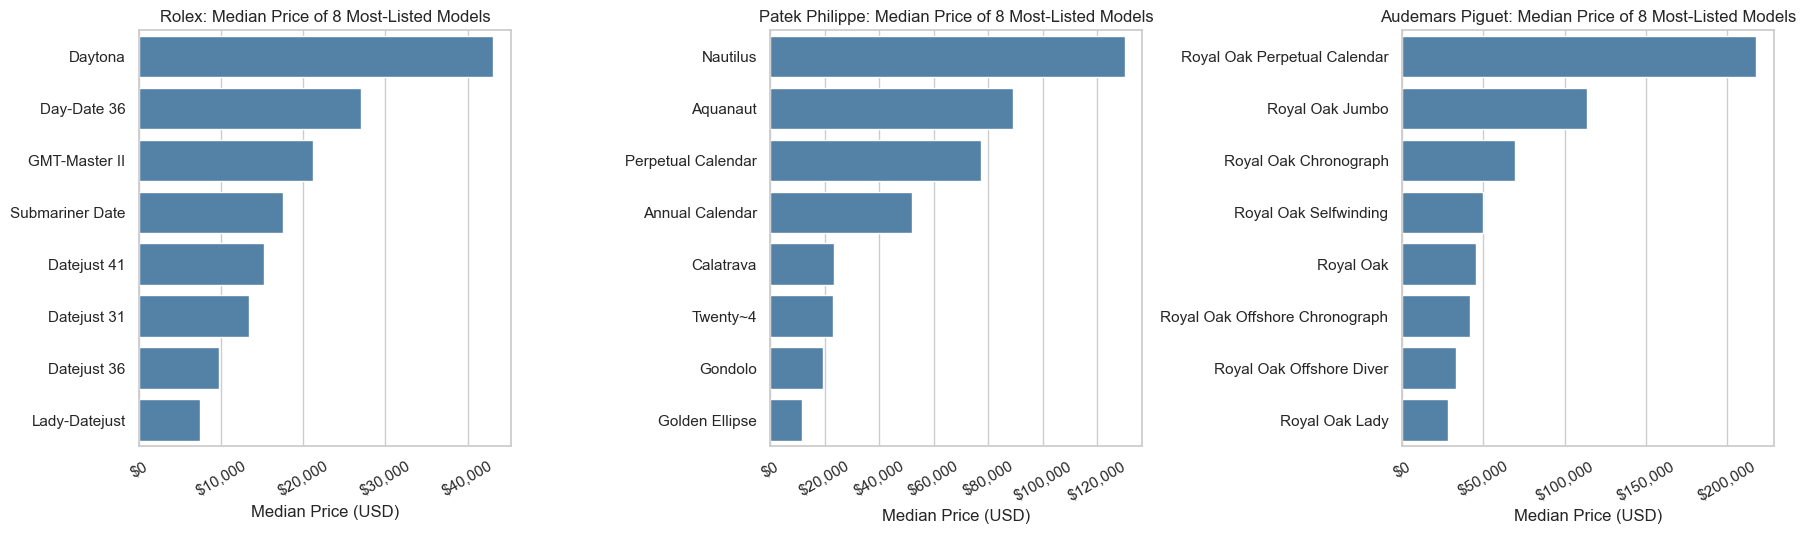

Share of log-price variance explained by brand alone:      64.9%
Share of log-price variance explained by model line alone: 81.1%


In [10]:
# Median price of the 8 most-listed model lines of three brands
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for ax, brand in zip(axes, ["Rolex", "Patek Philippe", "Audemars Piguet"]):
    brand_models = listings[(listings["brand"] == brand)
                            & ~listings["model_line"].str.endswith(("| Other", "| Unknown"))]
    top_models = brand_models["model_line"].value_counts().nlargest(8).index
    model_medians = (brand_models[brand_models["model_line"].isin(top_models)]
                     .groupby("model_line")["price"].median().sort_values(ascending=False))
    model_medians.index = model_medians.index.str.replace(f"{brand} | ", "", regex=False)
    sns.barplot(x=model_medians.values, y=model_medians.index, color="steelblue", ax=ax)
    ax.set_title(f"{brand}: Median Price of 8 Most-Listed Models")
    ax.set_xlabel("Median Price (USD)")
    ax.set_ylabel("")
    ax.xaxis.set_major_formatter(dollar_format)
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
save_figure(fig, "price_by_model_line.png")
plt.show()

# How much of the variation in log price do brand and model line each explain on their own?
# We use group means to get a signal on acceptable price per group, then
# look at share of variance explained by group means, i.e. the R² of predicting each listing by its group's mean
def variance_explained_by(group_col):
    group_means = listings.groupby(group_col)["log_price"].transform("mean")
    return 1 - ((listings["log_price"] - group_means) ** 2).sum() / \
        ((listings["log_price"] - listings["log_price"].mean()) ** 2).sum()

print(f"Share of log-price variance explained by brand alone:      {variance_explained_by('brand'):.1%}")
print(f"Share of log-price variance explained by model line alone: {variance_explained_by('model_line'):.1%}")

**Observation:** Brand medians span a range of almost 500x, from USD 573 (Seiko) to USD 275,000 (Richard Mille). But **the model line adds a lot on top of the brand**: a Rolex Daytona has a median price about six times that of a Lady-Datejust, and a Patek Philippe Nautilus (median about USD 130,000) about 11 times that of a Golden Ellipse. 

So far based on our calculations, brand seems to explain about **65%** of the variation in log price, while model line seems to explain about **81%**. This shows that the model names, which were missing from the initial analysis, carry a large share of the price information.

### 3.3 Revisiting the Patek Philippe steel puzzle
The initial report found that **steel Patek Philippe watches have a higher median price than gold ones**, and suggested demand for steel sports models such as the Nautilus as a possible explanation, but Dataset 2 had no model names to test it. Dataset 1 does.

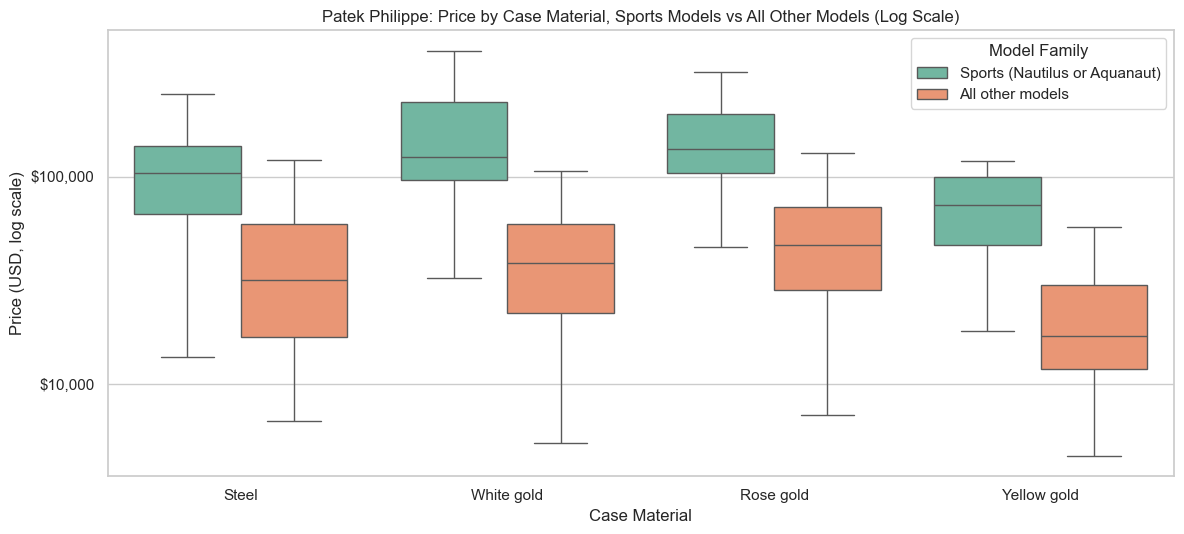

Median price ignoring model family: Rose gold $75,586, Steel $80,000, White gold $45,334, Yellow gold $18,791
Share of listings that are Nautilus/Aquanaut: Rose gold 39%, Steel 76%, White gold 19%, Yellow gold 11%
Median production year: Rose gold 2019, Steel 2018, White gold 2017, Yellow gold 1992
All other models: white/rose gold priced above steel? Mann-Whitney U p-value = 0.00017
Sports (Nautilus or Aquanaut): white/rose gold priced above steel? Mann-Whitney U p-value = 1.5e-29


In [11]:
patek = listings[(listings["brand"] == "Patek Philippe")
                 & listings["case_material"].isin(["Steel", "White gold", "Rose gold", "Yellow gold"])].copy()
patek["family"] = np.where(patek["model"].str.contains("Nautilus|Aquanaut", case=False),
                           "Sports (Nautilus or Aquanaut)", "All other models")

fig, ax = plt.subplots(figsize=(12, 5.5))
sns.boxplot(data=patek, x="case_material", y="price", hue="family",
            order=["Steel", "White gold", "Rose gold", "Yellow gold"], palette="Set2", showfliers=False, ax=ax)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(dollar_format)
ax.set_title("Patek Philippe: Price by Case Material, Sports Models vs All Other Models (Log Scale)")
ax.set_xlabel("Case Material")
ax.set_ylabel("Price (USD, log scale)")
ax.legend(title="Model Family")
plt.tight_layout()
save_figure(fig, "patek_steel_puzzle.png")
plt.show()

patek_summary = patek.groupby(["family", "case_material"])["price"].agg(median_price="median", listings="count")
display(patek_summary.unstack("case_material").style.format("{:,.0f}"))
# The puzzle as it appears when model family is ignored
overall = patek.groupby("case_material")["price"].median()
print("Median price ignoring model family: " + ", ".join(f"{m} ${p:,.0f}" for m, p in overall.items()))
sports_share = patek.groupby("case_material")["family"].apply(lambda f: f.eq("Sports (Nautilus or Aquanaut)").mean())
print("Share of listings that are Nautilus/Aquanaut: " + ", ".join(f"{m} {s:.0%}" for m, s in sports_share.items()))
print("Median production year: " + ", ".join(
    f"{m} {y:.0f}" for m, y in patek.groupby("case_material")["year"].median().items()))

# Mann-Whitney U test: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html
# We can use it to test if values from one group tend to be larger than values from another group. Here we use it to test if,
# within the same family, are white/rose gold cases priced higher than steel?
for family, group in patek.groupby("family"):
    white_or_rose = group["case_material"].isin(["White gold", "Rose gold"])
    steel = group["case_material"] == "Steel"
    mw = stats.mannwhitneyu(group.loc[white_or_rose, "price"], group.loc[steel, "price"], alternative="greater")
    print(f"{family}: white/rose gold priced above steel? Mann-Whitney U p-value = {mw.pvalue:.2g}")

**Result:** **The puzzle is solved: it was a model-mix effect, not a steel premium.** Ignoring model family, steel Pateks have the highest median price (USD 80,000), as in the initial report. But -based on the numbers in the table above- 76% of steel Patek listings are Nautilus or Aquanaut sports models, against 11-39% for the gold cases. **Within the same model family, white and rose gold are priced above steel** (As shown by the Mann-Whitney tests). Yellow gold stays the cheapest in both families; yellow-gold Pateks have a median production year of 1992 against 2017-2019 for the other metals, so they are typically older pieces, which may explain their lower prices. 

A **mix effect** happens when two groups are compared overall, but they contain different proportions of something else that also affects price. Here, steel Pateks look more expensive than gold ones not because steel is worth more, but because the steel group contains a much higher share of expensive Nautilus/Aquanaut models (a **model-mix effect**). The same thing happens with brands (a **brand-mix effect**, section 3.4).

### 3.4 Complications, diamonds and limited editions
Simple averages can mislead because features are not evenly spread across brands (the initial report found that *Used (Very good)* watches looked pricier than *New* ones largely because they came from pricier brands). To avoid this **brand-mix effect**, each feature is compared **within the same brand**: for each brand, the median price of listings *with* the feature is divided by the median price of listings *without* it. The chart shows the median of those within-brand ratios, and a two-sided Wilcoxon signed-rank (https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wilcoxon.html) test checks whether the ratios differ consistently from 1 across brands.

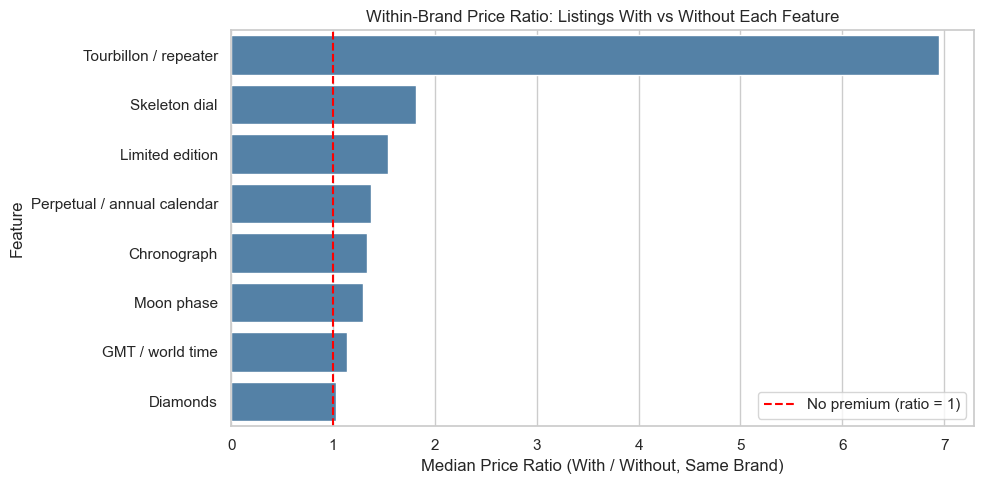

feature,brands compared,median within-brand ratio,brands where feature is pricier,Wilcoxon p-value
Tourbillon / repeater,11,6.95x,100%,0.001
Skeleton dial,8,1.81x,75%,0.1
Limited edition,18,1.54x,100%,8e-06
Perpetual / annual calendar,13,1.37x,85%,0.02
Chronograph,20,1.34x,85%,0.0002
Moon phase,13,1.30x,85%,0.02
GMT / world time,17,1.14x,71%,0.09
Diamonds,16,1.03x,50%,0.7


In [12]:
MIN_GROUP_LISTINGS = 20   # setting a reasonable threshold; both groups need this many listings in a brand for the brand to count


def within_brand_premium(df, has_feature, brand_col="brand", price_col="price"):
    """Per brand: median price with the feature / median price without it (brands with enough data only)."""
    grouped = df.groupby([df[brand_col], has_feature])[price_col].agg(["median", "count"]).unstack()
    enough = (grouped["count"] >= MIN_GROUP_LISTINGS).all(axis=1)
    return (grouped.loc[enough, ("median", True)] / grouped.loc[enough, ("median", False)]).rename("ratio")


feature_labels = {
    "is_chronograph": "Chronograph", "is_gmt": "GMT / world time",
    "is_calendar_complication": "Perpetual / annual calendar", "is_tourbillon_or_repeater": "Tourbillon / repeater",
    "is_moonphase": "Moon phase", "has_diamonds": "Diamonds", "is_skeleton": "Skeleton dial",
    "is_limited_edition": "Limited edition",
}
premium_rows = []
for flag, label in feature_labels.items():
    ratios = within_brand_premium(listings, listings[flag] == 1)
    if len(ratios) >= 5:   # need a few brands for the test to be meaningful
        p_value = stats.wilcoxon(np.log(ratios), alternative="two-sided").pvalue
        premium_rows.append({"feature": label, "brands compared": len(ratios),
                             "median within-brand ratio": ratios.median(),
                             "brands where feature is pricier": (ratios > 1).mean(),
                             "Wilcoxon p-value": p_value})

feature_premiums = pd.DataFrame(premium_rows).sort_values("median within-brand ratio", ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=feature_premiums, x="median within-brand ratio", y="feature", color="steelblue", ax=ax)
ax.axvline(1, color="red", linestyle="--", label="No premium (ratio = 1)")
ax.set_title("Within-Brand Price Ratio: Listings With vs Without Each Feature")
ax.set_xlabel("Median Price Ratio (With / Without, Same Brand)")
ax.set_ylabel("Feature")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

display(feature_premiums.style.format({"median within-brand ratio": "{:.2f}x",
                                       "brands where feature is pricier": "{:.0%}",
                                       "Wilcoxon p-value": "{:.1g}"}).hide(axis="index"))

**Observation:** Comparing within the same brand, **tourbillons and minute repeaters** have by far the largest premium (about 7x, higher in all 11 brands compared). **Limited editions (1.5x), calendar complications (1.4x), chronographs (1.3x) and moon phases (1.3x)** also carry consistent premiums (p < 0.05). GMT and skeleton watches show premiums that are not statistically significant, and diamonds show none at all (1.03x, p = 0.7). Note that limited editions have a slightly *negative* correlation with price overall (see the correlation heatmap below) yet are pricier within every one of the 18 brands compared: likely a brand-mix effect again, because limited editions are more common among less expensive brands (the highest shares are at Sinn, Seiko and Oris, 8-11% of their listings). This is why the within-brand comparison is used.

### 3.5 Case material, movement and condition
The same within-brand comparison is applied to the main categorical attributes, using the most common category as the reference (steel case, automatic movement, *Very good* condition).

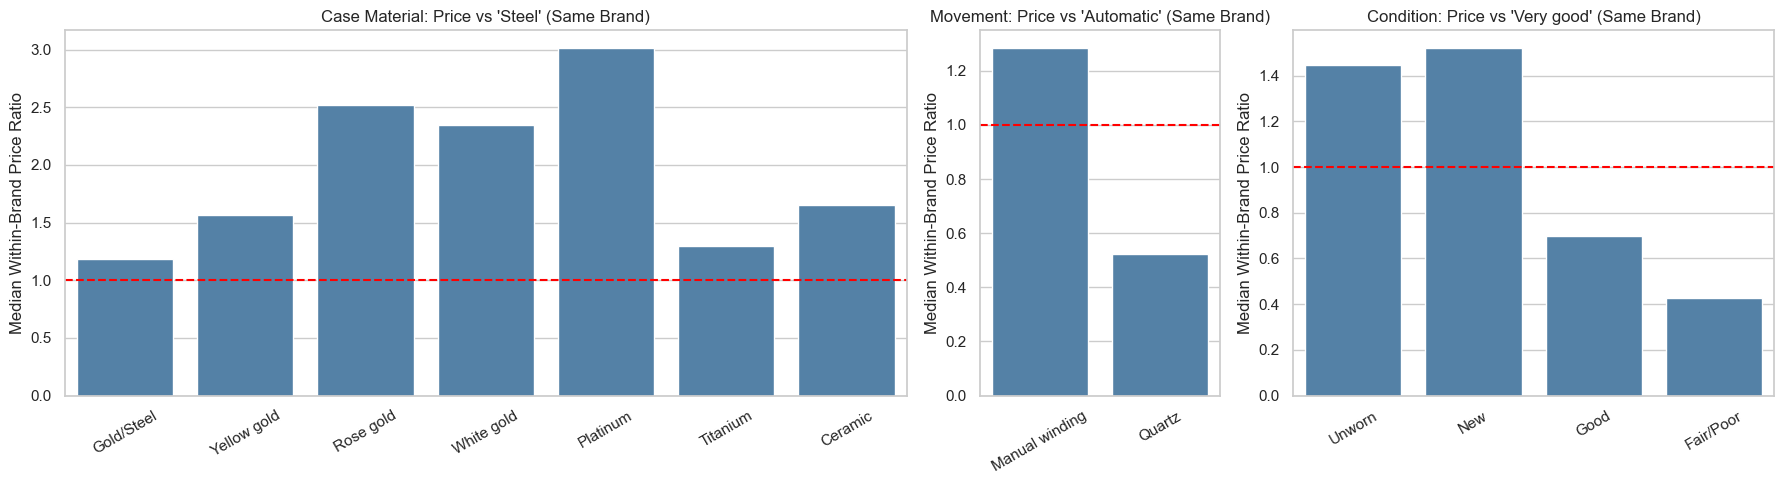

feature,category,reference,brands compared,median within-brand ratio
case_material,Gold/Steel,Steel,14,1.19x
case_material,Yellow gold,Steel,14,1.56x
case_material,Rose gold,Steel,13,2.52x
case_material,White gold,Steel,8,2.35x
case_material,Platinum,Steel,6,3.02x
case_material,Titanium,Steel,13,1.30x
case_material,Ceramic,Steel,10,1.65x
movement,Manual winding,Automatic,17,1.28x
movement,Quartz,Automatic,12,0.52x
condition,Unworn,Very good,20,1.45x


Brands with the most manual-winding listings: Omega 31%, Patek Philippe 15%, Panerai 12%, Jaeger-LeCoultre 9%
Chronograph share: manual winding 9.8%, automatic 16.1%
Rolex, price across condition grades: Kruskal-Wallis H = 9,474, p-value < 1e-300


In [13]:
comparisons = {
    "case_material": ("Steel", ["Gold/Steel", "Yellow gold", "Rose gold", "White gold", "Platinum",
                                "Titanium", "Ceramic"]),
    "movement": ("Automatic", ["Manual winding", "Quartz"]),
    "condition": ("Very good", ["Unworn", "New", "Good", "Fair/Poor"]),
}

ratio_rows = []
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [7, 2, 4]})
for ax, (column, (reference, categories)) in zip(axes, comparisons.items()):
    medians = []
    for category in categories:
        subset = listings[listings[column].isin([reference, category])]
        ratios = within_brand_premium(subset, subset[column] == category)
        medians.append(ratios.median())
        ratio_rows.append({"feature": column, "category": category, "reference": reference,
                           "brands compared": len(ratios), "median within-brand ratio": ratios.median()})
    sns.barplot(x=categories, y=medians, color="steelblue", ax=ax)
    ax.axhline(1, color="red", linestyle="--")
    ax.set_title(f"{column.replace('_', ' ').title()}: Price vs '{reference}' (Same Brand)")
    ax.set_xlabel("")
    ax.set_ylabel("Median Within-Brand Price Ratio")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

# Kruskal-Wallis test (https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kruskal.html): do log prices differ across conditions within Rolex (the largest brand)?
display(pd.DataFrame(ratio_rows).style.format({"median within-brand ratio": "{:.2f}x"}).hide(axis="index"))

# Which brands make up the manual-winding listings, and how many of them are chronographs?
manual = listings[listings["movement"] == "Manual winding"]
print("Brands with the most manual-winding listings: " + ", ".join(
    f"{brand} {share:.0%}" for brand, share in manual["brand"].value_counts(normalize=True).head(4).items()))
print(f"Chronograph share: manual winding {manual['is_chronograph'].mean():.1%}, "
      f"automatic {listings.loc[listings['movement'] == 'Automatic', 'is_chronograph'].mean():.1%}")

rolex = listings[(listings["brand"] == "Rolex") & (listings["condition"] != "Unknown")]
kw = stats.kruskal(*[group["log_price"] for _, group in rolex.groupby("condition")])
print(f"Rolex, price across condition grades: Kruskal-Wallis H = {kw.statistic:,.0f}, p-value {format_p(kw.pvalue)}")

**Observation:** Within the same brand, **precious metals carry large premiums over steel** (table above): platinum 3.02x, rose gold 2.52x, white gold 2.35x, yellow gold 1.56x and two-tone gold/steel 1.19x; titanium (1.30x) and ceramic (1.65x) are also above steel. Some of these ratios rest on few brands (platinum: 6, white gold: 8). **Quartz watches are listed at about half the price** of automatic ones (0.52x), while manual-winding watches are about 28% more expensive (1.28x). The data do not show why; manual-winding listings come mostly from Omega (31%), Patek Philippe (15%), Panerai (12%) and Jaeger-LeCoultre (9%), and they are *less* often chronographs than automatic ones (9.8% vs 16.1%). **Condition** matters: *New* (1.52x) and *Unworn* (1.45x) watches are priced about 1.5x *Very good* ones, *Good* about 0.7x and *Fair/Poor* about 0.4x. A Kruskal-Wallis test on Rolex alone confirms that price differs across condition grades (p < 0.001).

### 3.6 Case size and watch age (continuous features)
> *As was done in the initial report: the median price by production decade (right panel). New here: the case-size panel, the Rolex-only line and the correlation heatmap.*

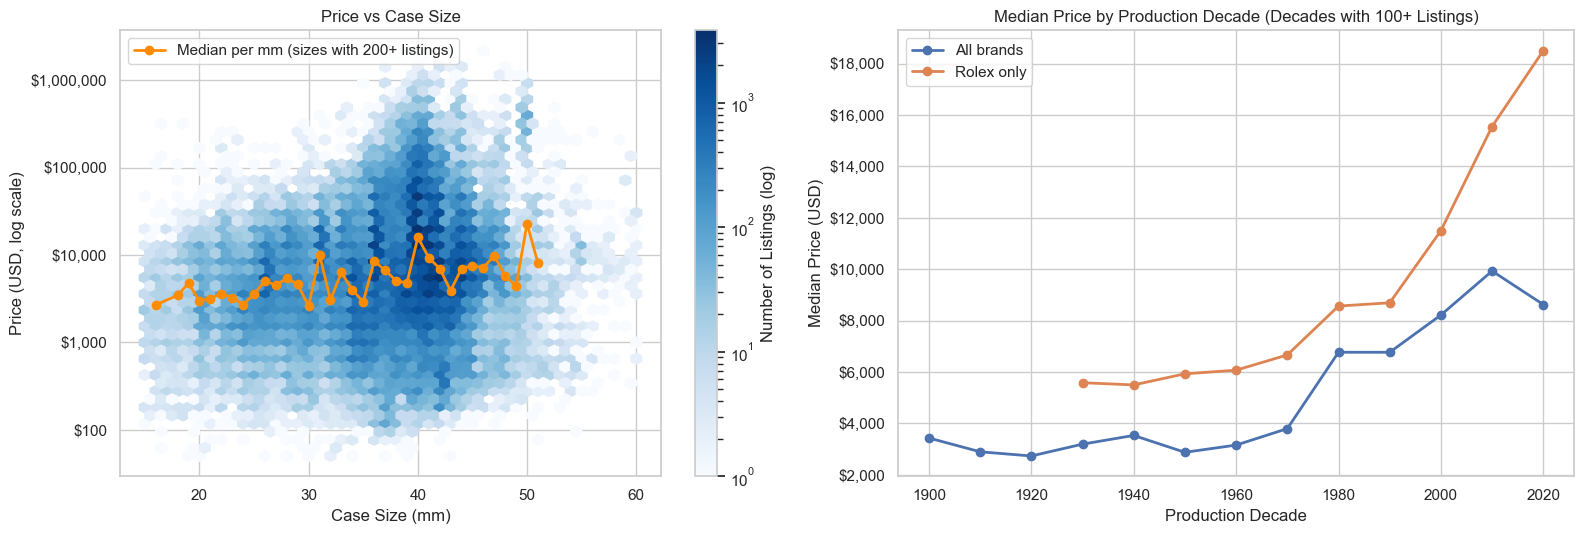

Spearman correlation, case size vs log price: 0.12 (p-value < 1e-300)
Share of listings with an unknown production year: 33.4%


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Case size: hexbin density, since 200k+ points would hide each other in a scatter plot
sized = listings.dropna(subset=["size_mm"])
hexbin = axes[0].hexbin(sized["size_mm"], sized["log_price"], gridsize=45, cmap="Blues", bins="log", mincnt=1)
size_medians = sized.groupby(sized["size_mm"].round())["log_price"].median()
size_medians = size_medians[sized["size_mm"].round().value_counts().reindex(size_medians.index) >= 200]
axes[0].plot(size_medians.index, size_medians.values, color="darkorange", marker="o", lw=2,
             label="Median per mm (sizes with 200+ listings)")
axes[0].set_title("Price vs Case Size")
axes[0].set_xlabel("Case Size (mm)")
axes[0].set_ylabel("Price (USD, log scale)")
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${10 ** v:,.0f}"))
axes[0].legend(loc="upper left")
fig.colorbar(hexbin, ax=axes[0], label="Number of Listings (log)")

# Watch age: median price by production decade, overall and within Rolex
dated = listings.dropna(subset=["year"]).copy()
dated["decade"] = (dated["year"] // 10 * 10).astype(int)
for subset, label in [(dated, "All brands"), (dated[dated["brand"] == "Rolex"], "Rolex only")]:
    by_decade = subset.groupby("decade")["price"].agg(["median", "count"]).query("count >= 100")
    axes[1].plot(by_decade.index, by_decade["median"], marker="o", lw=2, label=label)
axes[1].yaxis.set_major_formatter(dollar_format)
axes[1].set_title("Median Price by Production Decade (Decades with 100+ Listings)")
axes[1].set_xlabel("Production Decade")
axes[1].set_ylabel("Median Price (USD)")
axes[1].legend()

plt.tight_layout()
plt.show()

spearman = stats.spearmanr(sized["size_mm"], sized["log_price"])
print(f"Spearman correlation, case size vs log price: {spearman.statistic:.2f} (p-value {format_p(spearman.pvalue)})")
print(f"Share of listings with an unknown production year: {listings['year_missing'].mean():.1%}")

**Observation:** **Case size has only a weak link with price** (Spearman correlation 0.12). The median price per millimetre is noisy: it is about USD 2,700-5,000 for cases up to 26 mm and about USD 3,900-15,900 for 36-46 mm cases, jumping up and down rather than rising steadily. A likely reason is that size is mixed up with brand and model. **In these raw medians, newer watches are more expensive than older ones**: the median price is about USD 2,700-3,800 for every decade up to the 1970s, then rises to about USD 9,900 for the 2010s (USD 8,600 for the 2020s). The same upward trend appears within Rolex alone (from about USD 5,600 for the 1930s to USD 18,500 for the 2020s), so it is not only a change in brand mix. The relationship is not a straight line, which suits tree-based models. A third of listings have no production year. (Notebook 3 shows that once brand, model and other features are held fixed, the oldest watches carry a premium.)

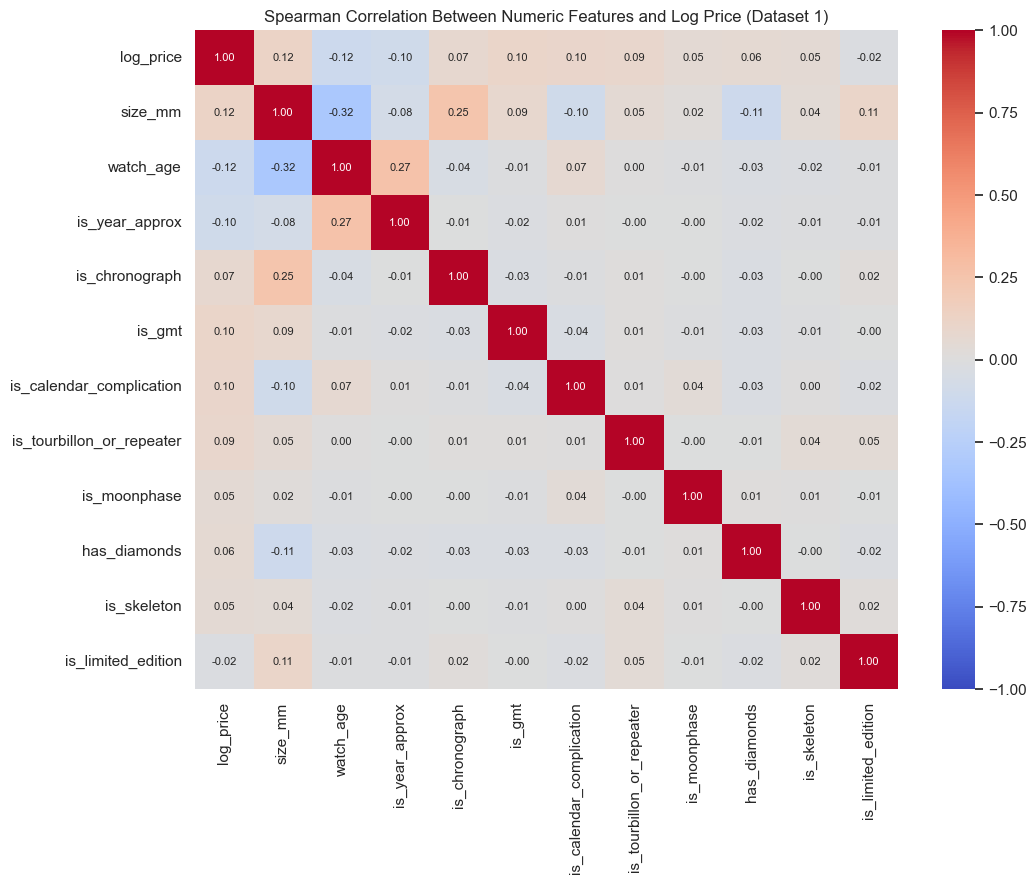

In [15]:
# Correlation between the numeric and binary features and log price
# (year_missing is left out: watch_age is always empty when it is 1, so their correlation is undefined)
numeric_cols = ["log_price", "size_mm", "watch_age", "is_year_approx"] + list(TEXT_FLAGS)
correlations = listings[numeric_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 8}, ax=ax)
ax.set_title("Spearman Correlation Between Numeric Features and Log Price (Dataset 1)")
plt.tight_layout()
plt.show()

**Observation:** No single numeric feature is strongly correlated with price (all |r| ≤ 0.13), consistent with price being driven mainly by the **categorical** features, brand and model line. The features are also only weakly correlated with each other, so multicollinearity is not a concern; the strongest links are that older watches tend to be smaller (-0.32), approximate years go with older watches (+0.27) and chronographs tend to be larger (+0.25).

## 4. Dataset 2: Watch Market Dataset
[Source: Kaggle](https://www.kaggle.com/datasets/beridzeg45/watch-prices-dataset). About 45,000 listings from 479 brands. It has no model names, but it records two things Dataset 1 lacks: **scope of delivery** (original box and papers) and **seller information** (trusted-seller badge, reviews, number of watches sold). Notebook 4 uses it to measure how much these are worth.

### 4.1 Cleaning and feature engineering
> *As was done in the initial report: dropping rows without a price, filling missing categories, removing duplicates, the outlier rules, the box & papers flags, watch age and grouping rare brands. New here: fixing impossible face areas and years, and the extra dial, crystal, shape and seller features.*

Carried over from the initial report: drop rows without a price, strip whitespace, fill missing categories with `Unknown`, drop duplicates, apply the same outlier rules, and create `has_box`, `has_papers`, `watch_age`, `year_missing` and `log_price`. Brands with fewer than 30 listings, and materials, crystals, dial colours and case shapes with fewer than 100, are grouped into `Other`.

New for the final project: `face_area` (dial area in mm²; impossible values such as 3 x 10^11 mm² are set to missing) and `water_resistance` are kept as numbers, production years outside 1900-2024 are set to missing as in Dataset 1, crystal, dial colour and case shape are kept as categories, and the seller columns are cleaned (`seller_reviews` and `seller_watches_sold` counts plus the 0/1 badges `trusted_seller`, `fast_shipper` and `punctual_seller`).

In [16]:
MIN_BRAND_LISTINGS_DS2 = 30

market = pd.read_csv(DATA_DIR / "watches-ds-2.csv")
print(f"Dataset 2 shape: {market.shape}")

market = market.dropna(subset=["Price"])
market = market.rename(columns={
    "Brand": "brand", "Movement": "movement", "Case material": "case_material",
    "Bracelet material": "bracelet_material", "Year of production": "year", "Condition": "condition",
    "Scope of delivery": "scope_of_delivery", "Gender": "gender", "Price": "price", "Shape": "shape",
    "Face Area": "face_area", "Water resistance": "water_resistance", "Crystal": "crystal", "Dial": "dial",
    "Watches Sold by the Seller": "seller_watches_sold", "Seller Reviews": "seller_reviews",
    "Fast Shipper": "fast_shipper", "Trusted Seller": "trusted_seller", "Punctuality": "punctual_seller",
})
categorical_cols_ds2 = ["brand", "movement", "case_material", "bracelet_material", "condition",
                        "scope_of_delivery", "gender", "shape", "crystal", "dial"]
market[categorical_cols_ds2] = market[categorical_cols_ds2].apply(lambda col: col.str.strip()).fillna("Unknown")
market = market[["price"] + categorical_cols_ds2 + ["year", "face_area", "water_resistance", "seller_reviews",
                                                    "seller_watches_sold", "fast_shipper", "trusted_seller",
                                                    "punctual_seller"]]

# Face area (mm²) contains impossible values (up to about 3 x 10^11). A 15-60 mm case has an area of roughly
# 180-2,800 mm², so values outside 100-4,000 mm² are treated as missing. Years use the same 1900-2024 bounds as Dataset 1.
implausible_area = market["face_area"].notna() & ~market["face_area"].between(100, 4000)
implausible_year = market["year"].notna() & ~market["year"].between(MIN_YEAR, MAX_YEAR)
print(f"Implausible face areas set to missing: {implausible_area.sum():,}; implausible years: {implausible_year.sum():,}")
market.loc[implausible_area, "face_area"] = np.nan
market.loc[implausible_year, "year"] = np.nan

rows_before = len(market)
market = market.drop_duplicates()
print(f"Duplicate rows removed: {rows_before - len(market):,}")
market = remove_price_outliers(market, "price")

scope = market["scope_of_delivery"]
market["has_box"] = scope.str.startswith("Original box").astype(int)
market["has_papers"] = (scope.str.contains("original papers", case=False)
                        & ~scope.str.contains("no original papers")).astype(int)
market["watch_age"] = DATA_COLLECTION_YEAR - market["year"]
market["year_missing"] = market["year"].isna().astype(int)
market["brand"] = group_rare(market["brand"], MIN_BRAND_LISTINGS_DS2)
for col in ["case_material", "bracelet_material", "crystal", "dial", "shape"]:
    market[col] = group_rare(market[col], MIN_MATERIAL_LISTINGS)
market["log_price"] = np.log10(market["price"])

print(f"Dataset 2 shape after cleaning: {market.shape}; distinct brands after grouping: {market['brand'].nunique()}")
display(market[["scope_of_delivery", "has_box", "has_papers"]].value_counts().rename("listings").to_frame())

Dataset 2 shape: (45024, 23)
Implausible face areas set to missing: 153; implausible years: 50
Duplicate rows removed: 451
Log-scale bounds: $1 to $3,754,226; listings under $50: 85
Rows removed: 86 (0.20%)
Dataset 2 shape after cleaning: (42214, 24); distinct brands after grouping: 284


,,,listings
scope_of_delivery,has_box,has_papers,
"Original box, original papers",1,1,26285
"No original box, no original papers",0,0,11244
"Original box, no original papers",1,0,3654
"Original papers, no original box",0,1,1031


## 5. Dataset 2: Exploratory Data Analysis

### 5.1 Box & papers, within the same brand
> *As was done in the initial report: the price by scope of delivery boxplot across all brands (left panel). New here: the within-brand comparison (right panel) and the statistical tests.*

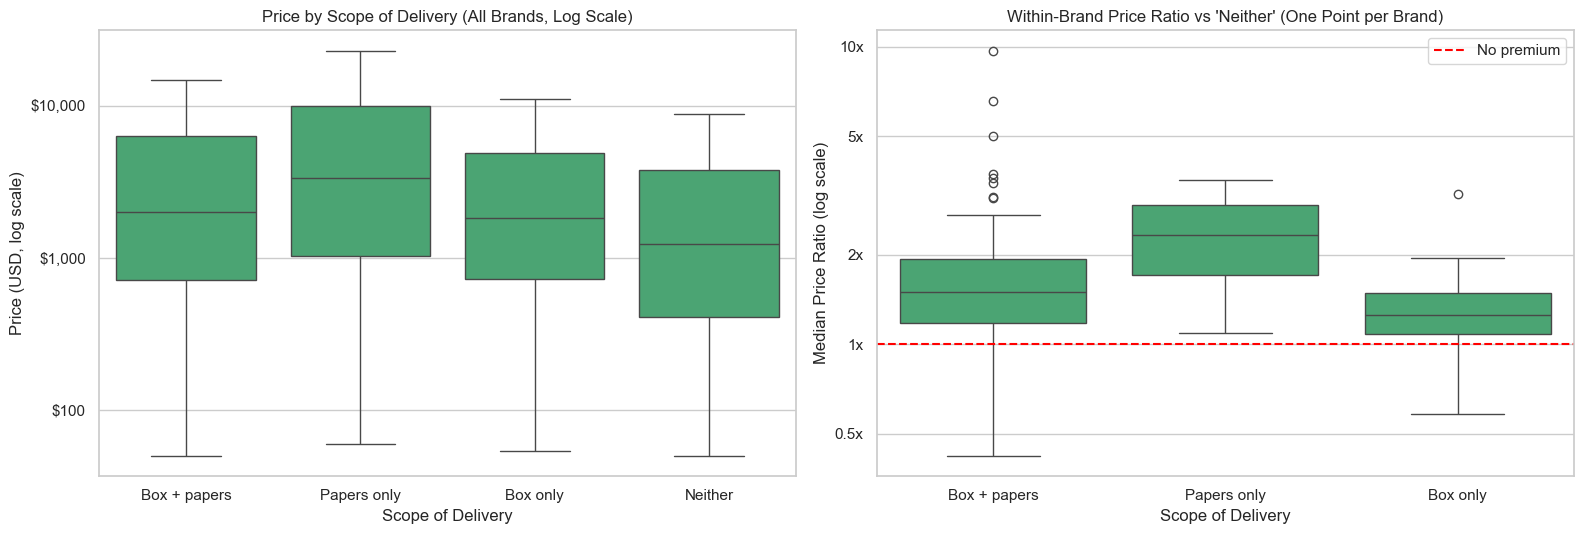

Median watch age (known years): Box + papers 1 yrs, Box only 13 yrs, Neither 52 yrs, Papers only 11 yrs
Share New or Unworn: Box + papers 40%, Box only 14%, Neither 3%, Papers only 9%


delivery,brands compared,median within-brand ratio,brands where it is pricier,Wilcoxon p-value
Box + papers,130,1.50x,83%,2e-16
Papers only,2,2.32x,100%,0.5
Box only,50,1.26x,84%,2e-07


In [17]:
scope_labels = {
    "Original box, original papers": "Box + papers",
    "Original papers, no original box": "Papers only",
    "Original box, no original papers": "Box only",
    "No original box, no original papers": "Neither",
}
market["delivery"] = market["scope_of_delivery"].map(scope_labels).fillna("Unknown")
known_delivery = market[market["delivery"] != "Unknown"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

sns.boxplot(data=known_delivery, x="delivery", y="price", order=list(scope_labels.values()),
            color="mediumseagreen", showfliers=False, ax=axes[0])
axes[0].set_yscale("log")
axes[0].yaxis.set_major_formatter(dollar_format)
axes[0].set_title("Price by Scope of Delivery (All Brands, Log Scale)")
axes[0].set_xlabel("Scope of Delivery")
axes[0].set_ylabel("Price (USD, log scale)")

# Within-brand comparison against "Neither"
delivery_ratios = {}
for label in ["Box + papers", "Papers only", "Box only"]:
    subset = known_delivery[known_delivery["delivery"].isin([label, "Neither"])]
    delivery_ratios[label] = within_brand_premium(subset, subset["delivery"] == label)
ratio_frame = pd.DataFrame(delivery_ratios).melt(var_name="delivery", value_name="ratio").dropna()

sns.boxplot(data=ratio_frame, x="delivery", y="ratio", color="mediumseagreen", ax=axes[1])
axes[1].axhline(1, color="red", linestyle="--", label="No premium")
axes[1].set_yscale("log")
axes[1].set_yticks([0.5, 1, 2, 5, 10])
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}x"))
axes[1].yaxis.set_minor_formatter(NullFormatter())
axes[1].set_title("Within-Brand Price Ratio vs 'Neither' (One Point per Brand)")
axes[1].set_xlabel("Scope of Delivery")
axes[1].set_ylabel("Median Price Ratio (log scale)")
axes[1].legend()

plt.tight_layout()
plt.show()

summary_rows = []
for label, ratios in delivery_ratios.items():
    summary_rows.append({"delivery": label, "brands compared": len(ratios),
                         "median within-brand ratio": ratios.median(),
                         "brands where it is pricier": (ratios > 1).mean(),
                         "Wilcoxon p-value": stats.wilcoxon(np.log(ratios)).pvalue})
# Full sets differ in other ways too: age and condition by scope of delivery
print("Median watch age (known years): " + ", ".join(
    f"{label} {age:.0f} yrs" for label, age in known_delivery.groupby("delivery")["watch_age"].median().items()))
print("Share New or Unworn: " + ", ".join(
    f"{label} {share:.0%}" for label, share in
    known_delivery.groupby("delivery")["condition"].apply(lambda c: c.isin(["New", "Unworn"]).mean()).items()))
display(pd.DataFrame(summary_rows).style.format({"median within-brand ratio": "{:.2f}x",
                                                 "brands where it is pricier": "{:.0%}",
                                                 "Wilcoxon p-value": "{:.1g}"}).hide(axis="index"))

**Observation:** Across all brands, every group with box or papers has a higher median than *Neither*. **Within the same brand, a full set (box + papers) is priced about 1.5x higher than a watch with neither**, and higher in 83% of the 130 brands compared (Wilcoxon p < 0.001). Box only is about 1.26x (84% of 50 brands). *Papers only* is rare (1,031 listings) and only 2 brands have enough of it to compare, so that ratio is not reliable. These raw ratios also include other differences: full sets are much newer (median age 1 year vs 52 years for watches with neither, among listings with a known year) and are more often *New* or *Unworn* (40% vs 3%), so Notebook 4 isolates the box & papers effect with a model.

### 5.2 Seller reputation
Do trusted sellers, or sellers with many reviews, ask for higher prices for the same brand?

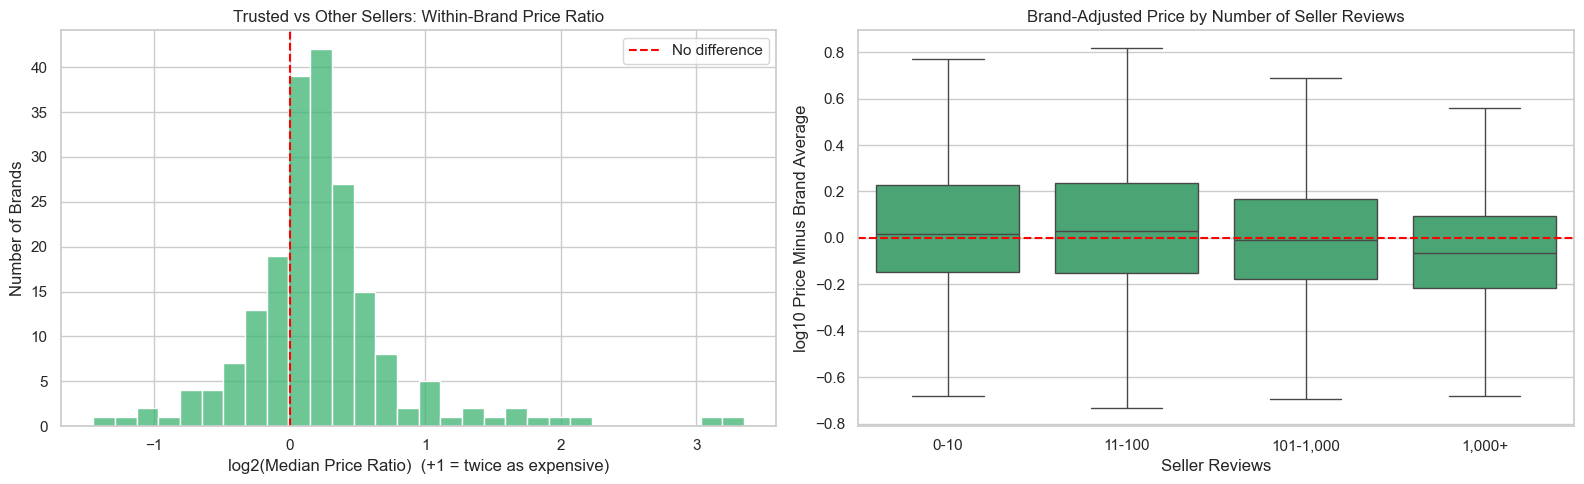

Trusted-seller share of listings: 62%
Trusted sellers priced higher in 73% of 201 brands; median ratio 1.16x, Wilcoxon p-value 2e-10
Spearman correlation, seller reviews vs brand-adjusted price: -0.13 (p-value = 1.5e-129)


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

trusted_ratios = within_brand_premium(market, market["trusted_seller"] == 1)
sns.histplot(np.log2(trusted_ratios), bins=30, color="mediumseagreen", ax=axes[0])
axes[0].axvline(0, color="red", linestyle="--", label="No difference")
axes[0].set_title("Trusted vs Other Sellers: Within-Brand Price Ratio")
axes[0].set_xlabel("log2(Median Price Ratio)  (+1 = twice as expensive)")
axes[0].set_ylabel("Number of Brands")
axes[0].legend()

reviewed = market.dropna(subset=["seller_reviews"]).copy()
reviewed["review_band"] = pd.cut(reviewed["seller_reviews"], bins=[-1, 10, 100, 1000, np.inf],
                                 labels=["0-10", "11-100", "101-1,000", "1,000+"])
# Brand-adjusted price: log price minus the brand's average log price
reviewed["brand_adjusted_log_price"] = reviewed["log_price"] - reviewed.groupby("brand")["log_price"].transform("mean")
sns.boxplot(data=reviewed, x="review_band", y="brand_adjusted_log_price", color="mediumseagreen",
            showfliers=False, ax=axes[1])
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Brand-Adjusted Price by Number of Seller Reviews")
axes[1].set_xlabel("Seller Reviews")
axes[1].set_ylabel("log10 Price Minus Brand Average")

plt.tight_layout()
plt.show()

print(f"Trusted-seller share of listings: {market['trusted_seller'].mean():.0%}")
print(f"Trusted sellers priced higher in {(trusted_ratios > 1).mean():.0%} of {len(trusted_ratios)} brands; "
      f"median ratio {trusted_ratios.median():.2f}x, Wilcoxon p-value {stats.wilcoxon(np.log(trusted_ratios)).pvalue:.1g}")
spearman_reviews = stats.spearmanr(reviewed["seller_reviews"], reviewed["brand_adjusted_log_price"])
print(f"Spearman correlation, seller reviews vs brand-adjusted price: {spearman_reviews.statistic:.2f} "
      f"(p-value = {spearman_reviews.pvalue:.2g})")

**Observation:** **Trusted sellers ask higher prices**: about 16% more than other sellers for the same brand (median ratio 1.16x, higher in 73% of 201 brands, Wilcoxon p < 0.001). The number of seller reviews shows the opposite, weak pattern: sellers with more than 1,000 reviews price slightly *below* the brand average (Spearman -0.13). A possible explanation is that high-volume dealers compete on price or stock more entry-level models within each brand; Notebook 4 checks whether these effects remain once the watch's own features are taken into account.

## 6. Cross-Checking the Two Datasets
The initial report suggested cross-referencing the datasets. They were published separately and have different columns, so a consistent picture across both would make the findings more trustworthy. The 20 brands in Dataset 1 are compared on their median price in each dataset.

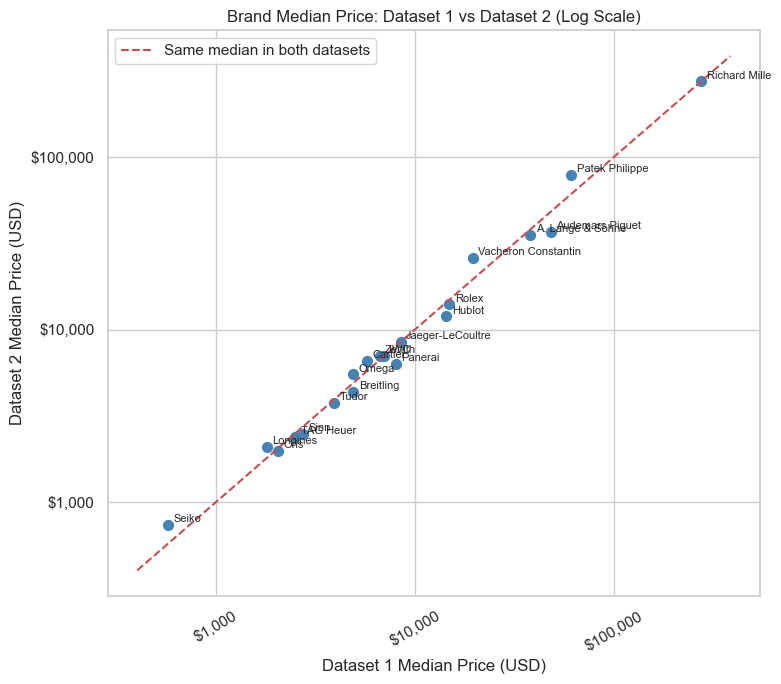

Brands in both datasets: 20
Spearman rank correlation of brand medians: 0.99 (p-value = 1e-15)
Dataset 2 median / Dataset 1 median, across brands: median 0.98x (range 0.77x to 1.34x)


In [19]:
brand_medians = pd.concat({
    "Dataset 1 median": listings.groupby("brand")["price"].median(),
    "Dataset 2 median": market.groupby("brand")["price"].median(),
    "Dataset 2 listings": market["brand"].value_counts(),
}, axis=1).dropna()

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(brand_medians["Dataset 1 median"], brand_medians["Dataset 2 median"], s=50, color="steelblue")
for brand, row in brand_medians.iterrows():
    ax.annotate(brand, (row["Dataset 1 median"], row["Dataset 2 median"]), fontsize=8,
                xytext=(4, 2), textcoords="offset points")
limits = [brand_medians[["Dataset 1 median", "Dataset 2 median"]].min().min() * 0.7,
          brand_medians[["Dataset 1 median", "Dataset 2 median"]].max().max() * 1.4]
ax.plot(limits, limits, "r--", label="Same median in both datasets")
ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(dollar_format)
ax.yaxis.set_major_formatter(dollar_format)
ax.tick_params(axis="x", rotation=30)
ax.set_title("Brand Median Price: Dataset 1 vs Dataset 2 (Log Scale)")
ax.set_xlabel("Dataset 1 Median Price (USD)")
ax.set_ylabel("Dataset 2 Median Price (USD)")
ax.legend()
plt.tight_layout()
plt.show()

rank_corr = stats.spearmanr(brand_medians["Dataset 1 median"], brand_medians["Dataset 2 median"])
ratio = brand_medians["Dataset 2 median"] / brand_medians["Dataset 1 median"]
print(f"Brands in both datasets: {len(brand_medians)}")
print(f"Spearman rank correlation of brand medians: {rank_corr.statistic:.2f} (p-value = {rank_corr.pvalue:.1g})")
print(f"Dataset 2 median / Dataset 1 median, across brands: median {ratio.median():.2f}x "
      f"(range {ratio.min():.2f}x to {ratio.max():.2f}x)")

**Observation:** The two datasets agree closely. The brand ranking is almost identical (Spearman rank correlation 0.99), and the median ratio between the two datasets' brand medians is 0.98x (individual brands range from 0.77x to 1.34x). The price patterns are therefore consistent across both datasets.

## 7. Saving the Cleaned Data
The cleaned datasets are saved as Parquet files (faster to load and they keep column types) for the next notebooks.

In [20]:
listings_features = ["price", "log_price", "brand", "model", "model_line", "movement", "case_material",
                     "bracelet_material", "condition", "gender", "size_mm", "year", "watch_age", "year_missing",
                     "is_year_approx"] + list(TEXT_FLAGS)
listings[listings_features].reset_index(drop=True).to_parquet(PROCESSED_DIR / "listings_clean.parquet")

market.drop(columns=["delivery"]).reset_index(drop=True).to_parquet(PROCESSED_DIR / "market_clean.parquet")
print(f"Saved Dataset 1: {len(listings):,} rows x {len(listings_features)} columns")
print(f"Saved Dataset 2: {len(market):,} rows x {market.shape[1] - 1} columns")

Saved Dataset 1: 260,648 rows x 23 columns
Saved Dataset 2: 42,214 rows x 24 columns


## 8. Summary of Findings
1. **Price is extremely skewed** (median USD 6,775, max USD 2.25M), so all models predict `log10(price)`.
2. **Brand and model line dominate.** Brand alone explains about 65% of the variation in log price; model line explains about 81%. Within a single brand, model lines differ in median price by more than 10x.
3. **The Patek Philippe "steel premium" was a model-mix effect.** Most steel Pateks are Nautilus/Aquanaut sports models; within the same model family, white and rose gold are worth more than steel.
4. **Complications add value within a brand:** tourbillons/repeaters (about 7x), limited editions (1.5x), calendar complications (1.4x), chronographs and moon phases (1.3x). Diamonds add no consistent premium.
5. **Materials, movement and condition matter:** platinum about 3x and rose/white gold about 2.4-2.5x steel; quartz about half the price of automatic; *New/Unworn* about 1.5x *Very good*.
6. **A full set (box + papers) is worth about 1.5x a watch with neither**, and trusted sellers ask about 16% more, for the same brand.
7. **Size and age have weak or non-linear relationships with price**, and the two datasets give a consistent picture (brand ranking correlation 0.99).

**Next:** [Notebook 2](02_model_training_and_tuning.ipynb) trains and tunes models on Dataset 1 to measure how much each group of features adds to price prediction.